In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print('Libraries loaded')

Libraries loaded


### Join the supervised stressed_state label onto the unsupervised archetype panel

This notebook continues the archetype series (after `03_balanced_clustering.ipynb`) by joining the supervised `stressed_state` label onto the labelled panel. Each active looping day gets its archetype (RQ1/RQ2) and whether it was a stressed day (from the supervised pipeline in `../whale-risk-supervised/`, RQ3). The archetypes were built without ever seeing the stress label, so the overlap is an independent cross-check of the two methods as well as a way to risk-grade the archetypes.

In [2]:
arch = pd.read_csv("panel_archetypes.csv", parse_dates=["date"])
lab = pd.read_csv("../whale-risk-supervised/whale_features_labeled.csv", parse_dates=["date"])

panel = arch.merge(
    lab[["whale_id", "date", "stressed_state"]],
    on=["whale_id", "date"],
    how="left",
)

matched = panel["stressed_state"].notna().sum()
print(f"{matched} of {len(panel)} archetype days matched a stressed_state label")
assert matched == len(panel), "some archetype days did not match a stressed_state label"
print(f"overall stressed share on active looping days: {panel['stressed_state'].mean() * 100:.1f}%")

1750 of 1750 archetype days matched a stressed_state label
overall stressed share on active looping days: 23.2%


Joined on `whale_id` and `date`, both shared across the two pipelines. All **1,750** active looping days find a label, so nothing is dropped. Overall **23.2%** (406/1,750) of days are flagged `stressed_state=1` under the per-whale model label. This is the baseline the per-archetype rates are compared against.

### Stressed share by archetype

In [3]:
ARCH_ORDER = ["moderate leverage", "high-LTV hold", "stale / light loop", "idle / outlier"]

by_arch = (
    panel.groupby("cluster_name")["stressed_state"]
    .agg(days="size", stressed_days="sum", stressed_pct="mean")
)
by_arch["stressed_pct"] = (by_arch["stressed_pct"] * 100).round(1)
by_arch = by_arch.reindex([a for a in ARCH_ORDER if a in by_arch.index])

panel.to_csv("panel_archetypes_stressed.csv", index=False)
by_arch

,days,stressed_days,stressed_pct
cluster_name,,,
moderate leverage,402,93,23.1
high-LTV hold,593,197,33.2
stale / light loop,667,98,14.7
idle / outlier,88,18,20.5


**Stressed share by archetype (per-whale label):**

| Archetype | Days | Stressed | % |
|---|---|---|---|
| high-LTV hold | 593 | 197 | **33.2** |
| moderate leverage | 402 | 93 | 23.1 |
| idle / outlier | 88 | 18 | 20.5 |
| stale / light loop | 667 | 98 | **14.7** |

Stress grades with leverage on the per-whale label. High-LTV hold leads at 33.2% (197/593 days); stale / light loop is lowest at 14.7% (98/667 days) because those days sit at lower LTV (mean 0.338) with a shallow per-whale stress tail (chiefly W-11 at 16.2% overall). The archetypes were built without the stress label, so the overlap is an independent cross-check.

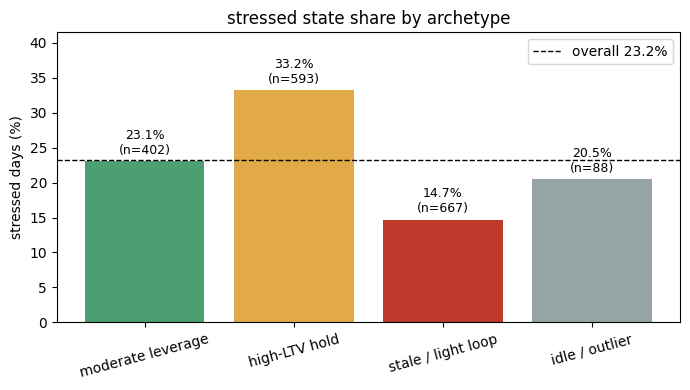

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = {"moderate leverage": "#4c9f70", "high-LTV hold": "#e1a948",
          "stale / light loop": "#c0392b", "idle / outlier": "#95a5a6"}
bars = ax.bar(by_arch.index, by_arch["stressed_pct"],
              color=[colors.get(a, "#888") for a in by_arch.index])
overall = panel["stressed_state"].mean() * 100
ax.axhline(overall, ls="--", c="k", lw=1, label=f"overall {overall:.1f}%")
for b, pct, n in zip(bars, by_arch["stressed_pct"], by_arch["days"]):
    ax.text(b.get_x() + b.get_width() / 2, pct + 0.6, f"{pct:.1f}%\n(n={n})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("stressed days (%)")
ax.set_title("stressed state share by archetype")
ax.set_ylim(0, max(by_arch["stressed_pct"]) * 1.25)
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Why stale / light loop shows fewer stressed days than high-LTV hold

`stressed_state` is defined per whale (the lowest slice of each whale's own health factor), so the absolute rate of an archetype depends on which whales populate it, not on raw leverage alone. The two tables below show the per-whale stressed rate and the whale make-up of each archetype.

In [5]:
per_whale = (lab.groupby("whale_id")["stressed_state"].mean() * 100).round(1)
print("stressed % per whale (all labelled days):")
print(per_whale.to_string())

print("\narchetype x whale day counts:")
print(pd.crosstab(panel["cluster_name"], panel["whale_id"]).to_string())

stressed % per whale (all labelled days):
whale_id
W-1      29.5
W-10     29.9
W-11     16.2
W-12     29.6
W-13     17.3
W-14     28.8
W-15     33.3
W-16     15.8
W-17    100.0
W-2      21.3
W-3      20.1
W-4      29.6
W-5      28.6
W-6      16.7
W-7      31.0
W-8      30.0
W-9      29.2

archetype x whale day counts:
whale_id            W-1  W-10  W-11  W-12  W-13  W-14  W-15  W-16  W-17  W-2  W-3  W-4  W-5  W-6  W-7  W-8  W-9
cluster_name                                                                                                   
high-LTV hold        28   202    10    70    80    62     1     0     0   81    4    0    0   38    1    1   15
idle / outlier        0    13     8     0    25    13     0    10     0    7   12    0    0    0    0    0    0
moderate leverage    27     0   163     0     6    29     7    19     0    0   78    7    7    0   46    6    7
stale / light loop   22    38   441     0    33     9     0     8     1    0   45   19   27    0   11   12    1


**Stale / light loop (667 days):**
- W-11 contributes 441 days (70.9% of its 622 total); W-11's overall stressed rate is only 16.2%.
- W-4 (73.1%), W-5 (79.4%), W-8 (63.2%) also sit here.
- Mean LTV 0.338 → these are lower-leverage days, so each whale's bottom-30% HF slice is shallow.
- Archetype stressed rate: 14.7% (98/667).

**High-LTV hold (593 days):**
- W-2 (92.0%, 81 days), W-6 (100%, 38 days), W-12 (100%, 70 days), W-10 (79.8%, 202 days), W-13 (55.6%, 80 days), W-14 (54.9%, 62 days), W-9 (65.2%, 15 days).
- Mean LTV 0.900 → the max-LTV pole; these are each whale's most stressed tail.
- Archetype stressed rate: 33.2% (197/593).

The cross-archetype ranking under the per-whale label still depends on whale mix. The absolute health-factor cut below removes that confound.

### Absolute health-factor stress measure (adopted as primary)

The per-whale label grades each whale against its own worst days, which is a within-whale view rather than a fair comparison between archetypes. Here we judge every whale on the same absolute buffer (lower health factor, closer to liquidation, counts as stressed) and adopt this as the cross-archetype risk measure, saved as `stressed_abs` (health factor < 1.05) alongside the panel. A few buffers are shown so the result does not hinge on one magic number.

In [6]:
chk = panel.merge(lab[["whale_id", "date", "health_factor"]], on=["whale_id", "date"], how="left")
panel["health_factor"] = chk["health_factor"].to_numpy()

# absolute, cross-whale stress measure: within 5% of liquidation (health factor < 1.05)
ABS_HF = 1.05
panel["stressed_abs"] = (panel["health_factor"] < ABS_HF).astype(int)
panel.to_csv("panel_archetypes_stressed.csv", index=False)

cmp = pd.DataFrame({"per-whale label %": by_arch["stressed_pct"]})
for thr in [1.05, 1.10, 1.15]:
    rate = (
        panel.assign(s=(panel["health_factor"] < thr).astype(int))
        .groupby("cluster_name")["s"].mean() * 100
    ).round(1)
    cmp[f"HF<{thr} %"] = rate
cmp.reindex(ARCH_ORDER)

,per-whale label %,HF<1.05 %,HF<1.1 %,HF<1.15 %
cluster_name,,,,
moderate leverage,23.1,34.6,43.8,57.5
high-LTV hold,33.2,63.7,86.0,98.8
stale / light loop,14.7,5.1,12.0,28.9
idle / outlier,20.5,13.6,20.5,23.9


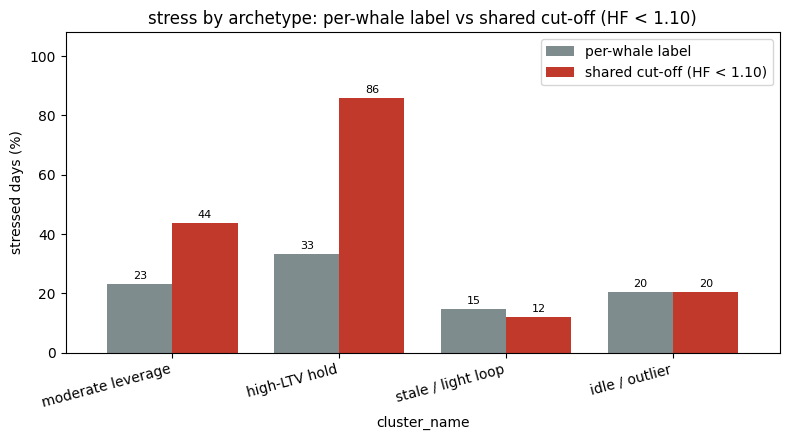

In [7]:
plot_df = cmp.reindex(ARCH_ORDER)[["per-whale label %", "HF<1.1 %"]]

ax = plot_df.plot(kind="bar", figsize=(8, 4.5), color=["#7f8c8d", "#c0392b"], width=0.78)
ax.set_ylabel("stressed days (%)")
ax.set_title("stress by archetype: per-whale label vs shared cut-off (HF < 1.10)")
ax.legend(["per-whale label", "shared cut-off (HF < 1.10)"])
ax.set_ylim(0, 108)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Absolute HF stress by archetype:**

| Archetype | HF&lt;1.05 % | HF&lt;1.10 % | HF&lt;1.15 % |
|---|---|---|---|
| high-LTV hold | **63.7** | 86.0 | 98.8 |
| moderate leverage | 34.6 | 43.8 | 57.5 |
| idle / outlier | 13.6 | 20.5 | 23.9 |
| stale / light loop | **5.1** | 12.0 | 28.9 |

On a shared cut-off the ordering tracks raw leverage: high-LTV hold is highest at every buffer (63.7% at HF&lt;1.05, 98.8% at HF&lt;1.15), moderate sits mid (35–58%), stale / light loop is lowest (5.1% at HF&lt;1.05), and idle stays low (~14–24%). Profile-based naming aligns archetype labels with this risk ranking. `stressed_abs` (HF&lt;1.05) is saved as the primary cross-archetype risk measure.

### Moderate leverage split by LTV (preview)

**Moderate leverage sub-split (402 days total):**

| LTV band | Days | Stressed | % |
|---|---|---|---|
| LTV &lt; 0.6 | 132 | 0 | **0.0** |
| LTV ≥ 0.6 | 270 | 93 | **34.4** |

Whale mix per band:
- **LTV &lt; 0.6:** W-11 (110 days), W-3 (9), W-16 (7), W-14 (6) — lower-leverage / partial-unwind days.
- **LTV ≥ 0.6:** W-3 (69), W-7 (46), W-1 (27), W-14 (23), W-11 (53), W-16 (12), W-15 (7), W-4 (7), W-5 (7), W-9 (7), W-8 (6), W-13 (6) — mid–high LTV active rebbalancers.

The split separates W-11's lighter-LTV stale days from the W-7/W-15/W-3 active-rebalance core. W-4 and W-5 now sit mostly in the stale / light loop archetype, not moderate.

In [8]:
mod = panel[panel["cluster_name"] == "moderate leverage"].copy()
mod["ltv_band"] = np.where(mod["ltv"] >= 0.6, "LTV >= 0.6", "LTV < 0.6")

mod_split = (
    mod.groupby("ltv_band")["stressed_state"]
    .agg(days="size", stressed_days="sum", stressed_pct="mean")
)
mod_split["stressed_pct"] = (mod_split["stressed_pct"] * 100).round(1)
print(mod_split.to_string())
print("\nwhale mix per band:")
print(mod.groupby("ltv_band")["whale_id"].value_counts().unstack(fill_value=0).to_string())

            days  stressed_days  stressed_pct
ltv_band                                     
LTV < 0.6    132              0           0.0
LTV >= 0.6   270             93          34.4

whale mix per band:
whale_id    W-1  W-11  W-13  W-14  W-15  W-16  W-3  W-4  W-5  W-7  W-8  W-9
ltv_band                                                                   
LTV < 0.6     0   110     0     6     0     7    9    0    0    0    0    0
LTV >= 0.6   27    53     6    23     7    12   69    7    7   46    6    7


### Next steps

- Calibrate the absolute health-factor threshold to something principled (observed liquidation events or each protocol's liquidation threshold) rather than the current hand-picked 5% buffer. Needs liquidation-event data.
- Use `strategist_type` and `moderate_sub` from `03` for whale-level mixed vs moderate-core splits.
- Split moderate leverage (`LTV < 0.6` vs `>= 0.6`) to separate W-3 partial-unwind days from W-7/W-15 mid-LTV holders.
- Cross stressed days with `days_since_rebalance` per archetype to test the RQ3 mechanism (stress driven by current LTV, rebalancing by accumulated LTV history).